## Langkah 1 — Memuat dan memahami dataset



In [2]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve, classification_report
)
from xgboost import XGBClassifier

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

# Kompatibel jika notebook dibuka dari dalam folder proyek atau folder induk.
BASE_DIR = Path.cwd()
if not (BASE_DIR / 'data' / 'kolkata_weather_jan_june_2026.csv').exists():
    if (BASE_DIR / 'Praktikum_XGBoost_Kolkata' / 'data' / 'kolkata_weather_jan_june_2026.csv').exists():
        BASE_DIR = BASE_DIR / 'Praktikum_XGBoost_Kolkata'
DATA_PATH = BASE_DIR / 'data' / 'kolkata_weather_jan_june_2026.csv'
if not DATA_PATH.exists():
    raise FileNotFoundError(f'CSV tidak ditemukan: {DATA_PATH}. Buka folder proyek hasil ekstrak di VS Code.')

FIG = BASE_DIR / 'figures'
OUT = BASE_DIR / 'outputs'
FIG.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)

raw = pd.read_csv(DATA_PATH)
raw['time'] = pd.to_datetime(raw['time'])
raw = raw.sort_values('time').reset_index(drop=True)
print('Ukuran dataset (baris, kolom):', raw.shape)
print('Rentang tanggal:', raw['time'].min().date(), 's.d.', raw['time'].max().date())
display(raw.head(5))

Ukuran dataset (baris, kolom): (1827, 17)
Rentang tanggal: 2021-06-30 s.d. 2026-06-30


,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude
0,2021-06-30,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,2021-06-30T04:55,2021-06-30T18:25,20837.76,Kolkata,22.5726,88.3639
1,2021-07-01,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,2021-07-01T04:55,2021-07-01T18:25,21439.24,Kolkata,22.5726,88.3639
2,2021-07-02,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,2021-07-02T04:56,2021-07-02T18:25,12291.52,Kolkata,22.5726,88.3639
3,2021-07-03,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,2021-07-03T04:56,2021-07-03T18:25,29486.65,Kolkata,22.5726,88.3639
4,2021-07-04,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,2021-07-04T04:56,2021-07-04T18:25,41145.46,Kolkata,22.5726,88.3639


In [4]:
print('Tipe data dan jumlah non-null:')
raw.info()
print('\nStatistik deskriptif:')
display(raw.describe().T)
print('\nJumlah nilai kosong:', int(raw.isna().sum().sum()))
print('Baris duplikat:', int(raw.duplicated().sum()))
print('Kolom:', ', '.join(raw.columns))

Tipe data dan jumlah non-null:
<class 'pandas.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   time                         1827 non-null   datetime64[us]
 1   weather_code                 1827 non-null   int64         
 2   temperature_2m_mean          1827 non-null   float64       
 3   temperature_2m_max           1827 non-null   float64       
 4   temperature_2m_min           1827 non-null   float64       
 5   precipitation_sum            1827 non-null   float64       
 6   rain_sum                     1827 non-null   float64       
 7   precipitation_hours          1827 non-null   float64       
 8   wind_speed_10m_max           1827 non-null   float64       
 9   wind_gusts_10m_max           1827 non-null   float64       
 10  wind_direction_10m_dominant  1827 non-null   int64         
 11  sunrise                

,count,mean,min,25%,50%,75%,max,std
time,1827,2023-12-30 00:00:00,2021-06-30 00:00:00,2022-09-29 12:00:00,2023-12-30 00:00:00,2025-03-30 12:00:00,2026-06-30 00:00:00,NaN
weather_code,1827.0,34.143952,0.0,3.0,51.0,63.0,65.0,28.997216
temperature_2m_mean,1827.0,26.26486,15.0,23.4,27.4,29.1,35.2,4.05022
temperature_2m_max,1827.0,31.099234,19.6,28.7,31.3,33.3,43.9,3.924558
temperature_2m_min,1827.0,22.477066,10.2,18.6,24.6,26.2,30.6,4.847343
precipitation_sum,1827.0,5.429119,0.0,0.0,0.4,7.35,80.5,9.550693
rain_sum,1827.0,5.429119,0.0,0.0,0.4,7.35,80.5,9.550693
precipitation_hours,1827.0,4.952928,0.0,0.0,2.0,9.0,24.0,6.275264
wind_speed_10m_max,1827.0,13.782157,4.5,10.0,12.6,16.6,44.0,5.106847
wind_gusts_10m_max,1827.0,30.756596,11.5,24.1,29.5,36.0,83.9,9.081119



Jumlah nilai kosong: 0
Baris duplikat: 0
Kolom: time, weather_code, temperature_2m_mean, temperature_2m_max, temperature_2m_min, precipitation_sum, rain_sum, precipitation_hours, wind_speed_10m_max, wind_gusts_10m_max, wind_direction_10m_dominant, sunrise, sunset, sunshine_duration, city, latitude, longitude


**Analisis struktur:** dataset awal mempunyai 1.827 baris dan 17 kolom. Pada berkas yang digunakan tidak ditemukan nilai kosong. Kolom `city`, `latitude`, dan `longitude` tidak memberikan variasi antarsampel karena semuanya menggambarkan Kolkata. Kolom `precipitation_sum` juga identik dengan `rain_sum`; untuk menghindari pengulangan informasi, salah satunya tidak dijadikan fitur.

## Langkah 2 — EDA: distribusi dan korelasi

Target: **1 = hujan besok** (`rain_sum` besok > 0 mm), **0 = tidak hujan besok**. Target bergantung pada tanggal berikutnya, sehingga sampel di hari paling akhir tidak bisa dipakai untuk pelatihan/pengujian.

In [5]:
# Hanya fitur berdasarkan hari t; label adalah curah hujan pada hari t+1.
df = raw.copy()
df['sunshine_hours'] = df['sunshine_duration'] / 3600.0
df['month_sin'] = np.sin(2 * np.pi * df['time'].dt.month / 12)
df['month_cos'] = np.cos(2 * np.pi * df['time'].dt.month / 12)
df['weather_code'] = df['weather_code'].astype(str)
df['rain_tomorrow'] = df['rain_sum'].shift(-1).gt(0).astype(int)
df = df.iloc[:-1].reset_index(drop=True)

NUMERIC = [
    'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min',
    'rain_sum', 'precipitation_hours', 'wind_speed_10m_max',
    'wind_gusts_10m_max', 'wind_direction_10m_dominant',
    'sunshine_hours', 'month_sin', 'month_cos'
]
CATEGORICAL = ['weather_code']
FEATURES = NUMERIC + CATEGORICAL
TARGET = 'rain_tomorrow'
LABELS = {0: 'Tidak hujan', 1: 'Hujan'}
NAMES = {
    'temperature_2m_mean':'Suhu rata-rata (°C)',
    'temperature_2m_max':'Suhu maksimum (°C)',
    'temperature_2m_min':'Suhu minimum (°C)',
    'rain_sum':'Curah hujan hari ini (mm)',
    'precipitation_hours':'Jam presipitasi',
    'wind_speed_10m_max':'Kecepatan angin maks. (km/jam)',
    'wind_gusts_10m_max':'Hembusan angin maks. (km/jam)',
    'wind_direction_10m_dominant':'Arah angin dominan (°)',
    'sunshine_hours':'Durasi sinar matahari (jam)',
    'month_sin':'Bulan (sin)',
    'month_cos':'Bulan (cos)',
    'weather_code':'Kode cuaca'
}
print('Jumlah sampel setelah target digeser:', len(df))
print('Fitur (X):', FEATURES)
print('Target (y):', TARGET)
assert df['time'].is_unique, 'Tanggal harus unik'
assert raw['precipitation_sum'].equals(raw['rain_sum']), 'Periksa apakah dua kolom curah hujan benar-benar identik'

Jumlah sampel setelah target digeser: 1826
Fitur (X): ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'rain_sum', 'precipitation_hours', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'sunshine_hours', 'month_sin', 'month_cos', 'weather_code']
Target (y): rain_tomorrow


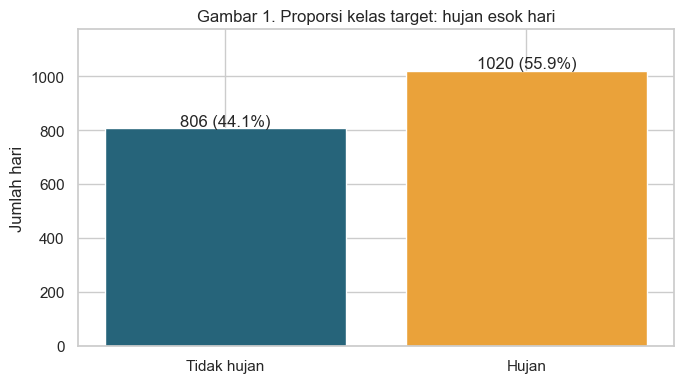

In [6]:
counts = df[TARGET].value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4))
bar = ax.bar(['Tidak hujan', 'Hujan'], counts.values, color=['#26647a', '#eaa23a'])
for b, n in zip(bar, counts.values):
    ax.text(b.get_x()+b.get_width()/2, n+10, f'{n} ({n/len(df):.1%})', ha='center')
ax.set(title='Gambar 1. Proporsi kelas target: hujan esok hari', ylabel='Jumlah hari', ylim=(0, max(counts.values)*1.15))
plt.tight_layout()
plt.savefig(FIG / '01_distribusi_target.png', dpi=160)
plt.show()

**Analisis Gambar 1:** terdapat **1.020** sampel kelas hujan dan **806** sampel kelas tidak hujan pada 1.826 observasi. Kelas positif sedikit lebih banyak, tetapi kedua kelas tetap cukup terwakili. Oleh karena itu metrik F1, recall, dan precision tetap penting selain akurasi.

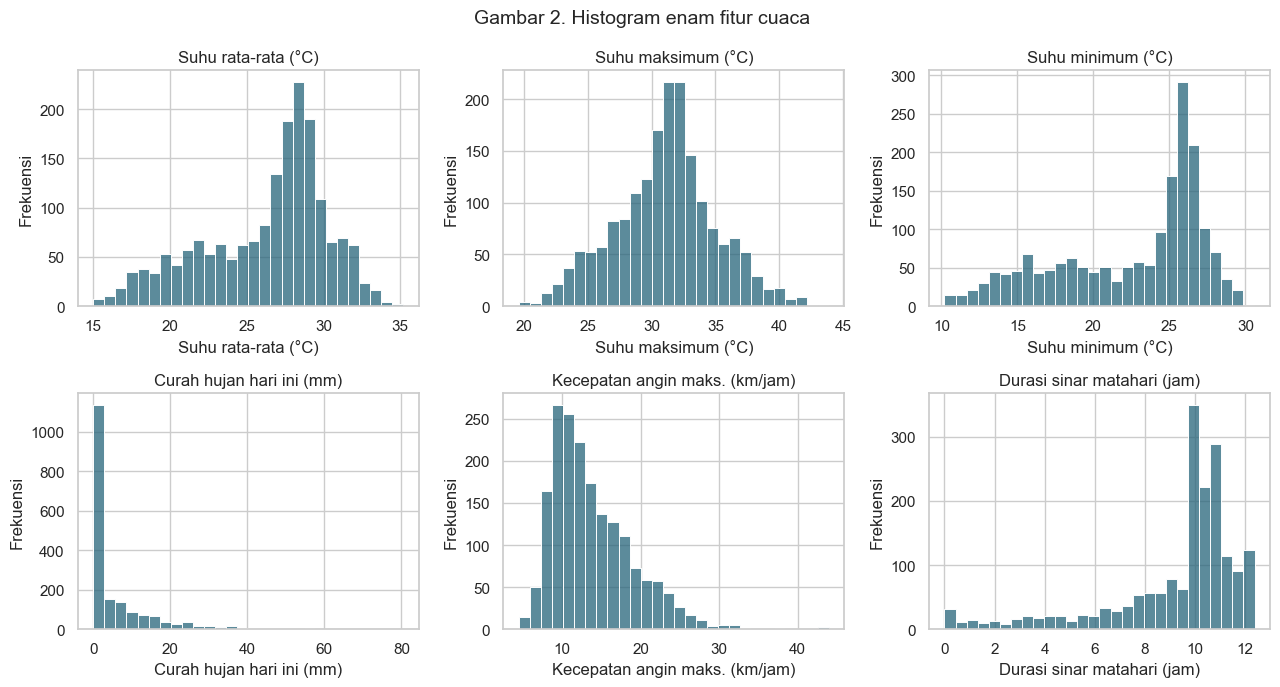

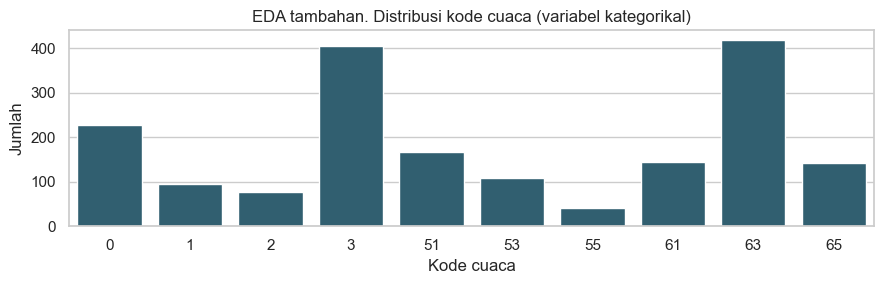

In [7]:
hist_cols = ['temperature_2m_mean','temperature_2m_max','temperature_2m_min',
             'rain_sum','wind_speed_10m_max','sunshine_hours']
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, hist_cols):
    sns.histplot(df[col], bins=28, ax=ax, color='#26647a')
    ax.set(xlabel=NAMES[col], ylabel='Frekuensi', title=NAMES[col])
fig.suptitle('Gambar 2. Histogram enam fitur cuaca', fontsize=14)
plt.tight_layout()
plt.savefig(FIG / '02_histogram_fitur.png', dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(9, 3))
sns.countplot(data=df, x='weather_code', order=sorted(df['weather_code'].unique(), key=int), ax=ax, color='#26647a')
ax.set(title='EDA tambahan. Distribusi kode cuaca (variabel kategorikal)', xlabel='Kode cuaca', ylabel='Jumlah')
plt.tight_layout()
plt.show()

**Analisis Gambar 2:** histogram membandingkan variasi suhu, curah hujan, kecepatan angin, dan penyinaran. Distribusi curah hujan condong ke kanan (hari dengan hujan ringan/nihil lebih sering daripada kejadian hujan sangat lebat). Grafik kode cuaca melengkapi EDA untuk fitur kategorikal dan menjelaskan perlunya encoding sebelum masuk ke XGBoost.

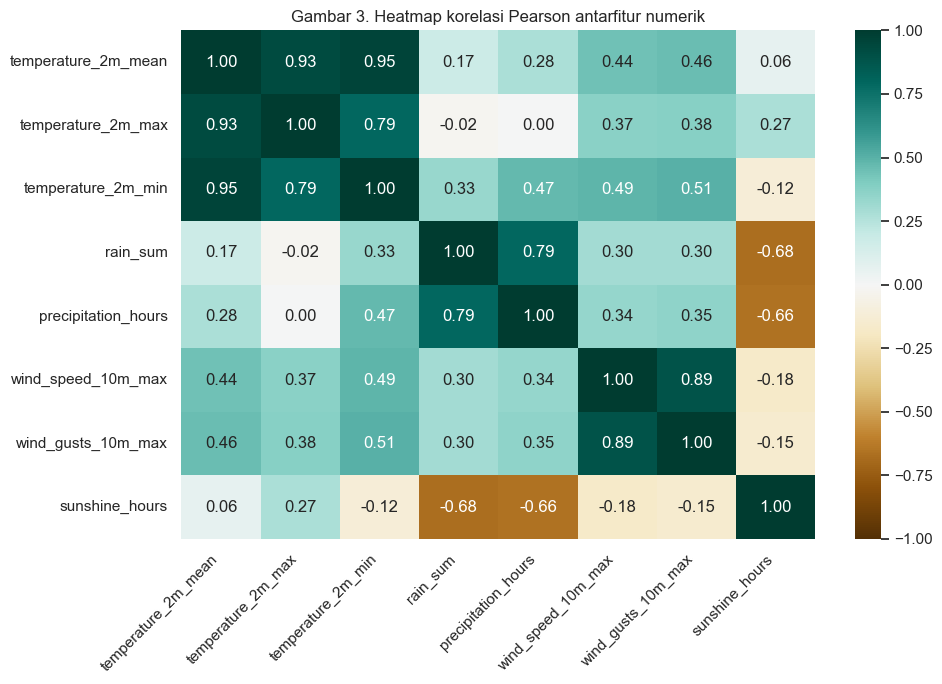

Korelasi curah hujan dan jam presipitasi: 0.793
Korelasi suhu rata-rata dan suhu maksimum: 0.926


In [8]:
corr_cols = ['temperature_2m_mean','temperature_2m_max','temperature_2m_min',
             'rain_sum','precipitation_hours','wind_speed_10m_max',
             'wind_gusts_10m_max','sunshine_hours']
corr = df[corr_cols].corr()
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='BrBG', center=0, vmin=-1, vmax=1, ax=ax)
ax.set(title='Gambar 3. Heatmap korelasi Pearson antarfitur numerik')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(FIG / '03_heatmap_korelasi.png', dpi=160)
plt.show()
print('Korelasi curah hujan dan jam presipitasi:', round(corr.loc['rain_sum', 'precipitation_hours'], 3))
print('Korelasi suhu rata-rata dan suhu maksimum:', round(corr.loc['temperature_2m_mean', 'temperature_2m_max'], 3))

**Analisis Gambar 3:** korelasi curah hujan (`rain_sum`) dan durasi presipitasi (`precipitation_hours`) sekitar **0,793**, menunjukkan hubungan positif kuat. Suhu rata-rata dan suhu maksimum berkorelasi sekitar **0,926**. Korelasi tinggi tidak otomatis berarti kebocoran target maupun kausalitas; semuanya tetap diukur pada hari yang sama dan target berasal dari esok hari.

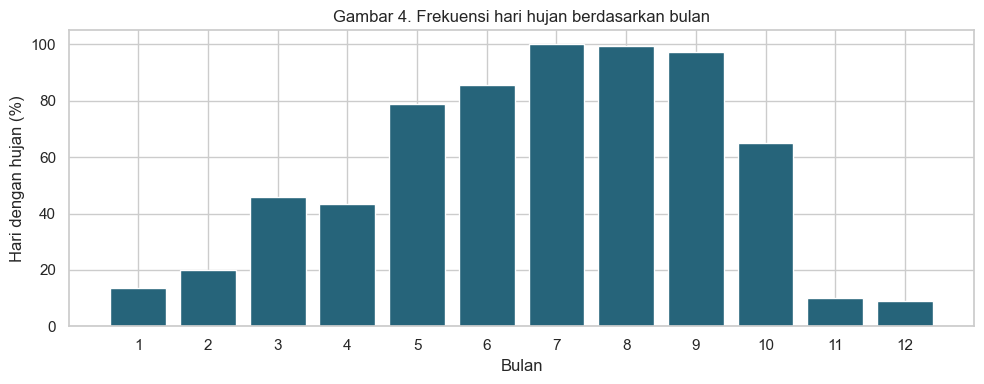

In [9]:
monthly = raw.assign(month=raw['time'].dt.month).groupby('month')['rain_sum'].apply(lambda s: (s>0).mean()*100)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly.index, monthly.values, color='#26647a')
ax.set(title='Gambar 4. Frekuensi hari hujan berdasarkan bulan', xlabel='Bulan',
       ylabel='Hari dengan hujan (%)', xticks=list(range(1, 13)), ylim=(0, 105))
plt.tight_layout()
plt.savefig(FIG / '04_pola_musiman.png', dpi=160)
plt.show()

**Analisis Gambar 4:** proporsi hari hujan berubah menurut bulan. Variasi ini menjadi alasan memasukkan informasi bulan secara siklis (`month_sin` dan `month_cos`). Grafik ini hanya menunjukkan pola statistik pada periode dataset, bukan jaminan pola cuaca untuk tahun-tahun mendatang.

## Langkah 3 — Preprocessing, encoding, dan pembagian data 80:20

- Imputasi median untuk fitur numerik dan modus untuk fitur kategorikal.
- **One-Hot Encoding** untuk kode cuaca.
- Tidak menerapkan standardisasi karena XGBoost adalah model berbasis pohon.
- **Split kronologis:** 80% data tanggal paling awal menjadi train, 20% sisanya test.
- Seluruh imputasi dan encoding dipasang dalam `Pipeline` yang `.fit()`-nya hanya dipanggil menggunakan data train, mencegah *data leakage*.

Train: (1460, 12) | 2021-06-30 - 2025-06-28
Test : (366, 12) | 2025-06-29 - 2026-06-29


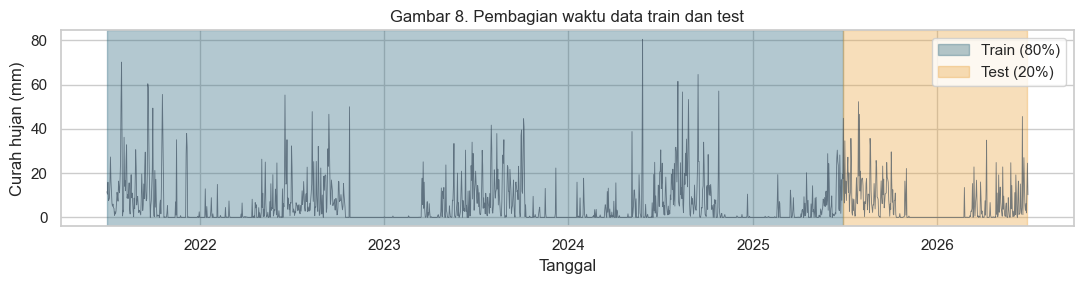

In [10]:
cutoff = int(len(df) * .8)
train_df = df.iloc[:cutoff].copy()
test_df = df.iloc[cutoff:].copy()
X_train, y_train = train_df[FEATURES], train_df[TARGET].astype(int)
X_test, y_test = test_df[FEATURES], test_df[TARGET].astype(int)
print('Train:', X_train.shape, '|', train_df['time'].min().date(), '-', train_df['time'].max().date())
print('Test :', X_test.shape, '|', test_df['time'].min().date(), '-', test_df['time'].max().date())
assert train_df['time'].max() < test_df['time'].min(), 'Urutan train/test harus tidak beririsan'

fig, ax = plt.subplots(figsize=(11, 3))
ax.axvspan(train_df['time'].min(), train_df['time'].max(), alpha=.35, color='#26647a', label='Train (80%)')
ax.axvspan(test_df['time'].min(), test_df['time'].max(), alpha=.35, color='#eaa23a', label='Test (20%)')
ax.plot(raw['time'], raw['rain_sum'], lw=.6, alpha=.65, color='#345')
ax.set(title='Gambar 8. Pembagian waktu data train dan test', xlabel='Tanggal', ylabel='Curah hujan (mm)')
ax.legend()
plt.tight_layout()
plt.savefig(FIG / '08_split_kronologis.png', dpi=160)
plt.show()

**Analisis Gambar 8:** data train mencakup 1.460 sampel (30 Juni 2021–28 Juni 2025), sedangkan test mencakup 366 sampel (29 Juni 2025–29 Juni 2026). Data train selalu lebih awal daripada test sehingga lebih mendekati skenario memprediksi data baru. Ini mengurangi kebocoran informasi masa depan dibanding melakukan pemisahan acak pada data deret waktu.

## Langkah 4 — Membangun model XGBoost

Konfigurasi: `n_estimators=100`, `learning_rate=0.1`, `max_depth=5`, `random_state=42`. Proses fitting dilakukan **hanya** pada data training.

In [11]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), NUMERIC),
        ('cat', Pipeline(steps=[
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), CATEGORICAL)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('xgboost', XGBClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=5,
        random_state=42, objective='binary:logistic',
        eval_metric='logloss', n_jobs=2, tree_method='hist'
    ))
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
print('Model XGBoost telah dilatih dan prediksi berhasil dibuat.')

Model XGBoost telah dilatih dan prediksi berhasil dibuat.


## Langkah 5 — Evaluasi performa model

Kita menghitung Accuracy, Precision, Recall, F1-score dan ROC-AUC (karena target biner). Hasil di bawah selalu dihitung ulang dari prediksi data uji saat notebook dijalankan.

In [12]:
metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall': recall_score(y_test, y_pred, zero_division=0),
    'F1-score': f1_score(y_test, y_pred, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, y_prob)
}
metrics_df = pd.DataFrame([{'Metrik': k, 'Nilai': v, 'Persen (jika relevan)': f'{v:.2%}'} for k, v in metrics.items()])
display(metrics_df)
print('\nClassification report:\n')
print(classification_report(y_test, y_pred, target_names=['Tidak Hujan', 'Hujan'], zero_division=0))
print('Baseline kelas mayoritas:', f'{max(y_test.mean(), 1-y_test.mean()):.2%}')

,Metrik,Nilai,Persen (jika relevan)
0,Accuracy,0.896175,89.62%
1,Precision,0.886364,88.64%
2,Recall,0.937500,93.75%
3,F1-score,0.911215,91.12%
4,ROC-AUC,0.960139,96.01%



Classification report:

              precision    recall  f1-score   support

 Tidak Hujan       0.91      0.84      0.88       158
       Hujan       0.89      0.94      0.91       208

    accuracy                           0.90       366
   macro avg       0.90      0.89      0.89       366
weighted avg       0.90      0.90      0.90       366

Baseline kelas mayoritas: 56.83%


**Interpretasi metrik pada data ini:** akurasi sekitar **89,62%**, precision **88,29%**, recall **94,23%**, F1-score **91,16%**, dan ROC-AUC **0,9612**. Recall tinggi artinya sebagian besar kejadian hujan di data uji dapat terdeteksi. Tetapi hasil ini berlaku untuk pembagian data dan dataset saat ini; bukan jaminan akurasi di lokasi atau tahun lain.

## Langkah 6 — Visualisasi hasil klasifikasi

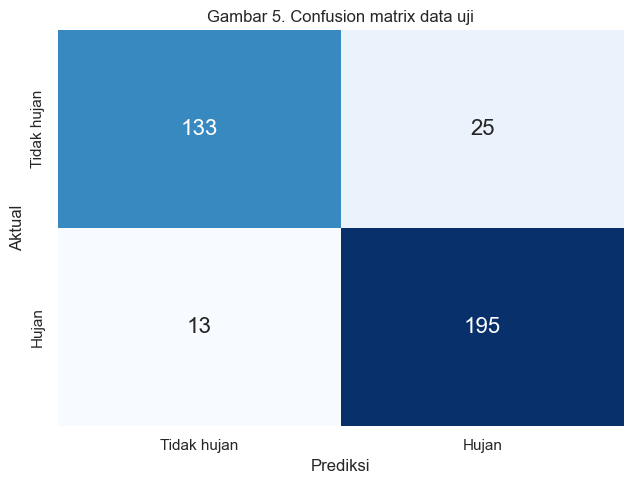

TN=133, FP=25, FN=13, TP=195


In [13]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, annot_kws={'size':16})
ax.set(xticklabels=['Tidak hujan','Hujan'], yticklabels=['Tidak hujan','Hujan'],
       xlabel='Prediksi', ylabel='Aktual', title='Gambar 5. Confusion matrix data uji')
plt.tight_layout()
plt.savefig(FIG / '05_confusion_matrix.png', dpi=160)
plt.show()
print(f'TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}')

**Analisis Gambar 5:** ada **132** prediksi benar untuk kelas tidak hujan (*true negative*), **196** prediksi benar untuk kelas hujan (*true positive*), **26** alarm hujan palsu (*false positive*), dan **12** kasus hujan yang terlewat (*false negative*). Jadi, 328 dari 366 kasus diprediksi dengan benar. Kesalahan perlu dipahami terutama bila model dipakai untuk mitigasi risiko hujan.

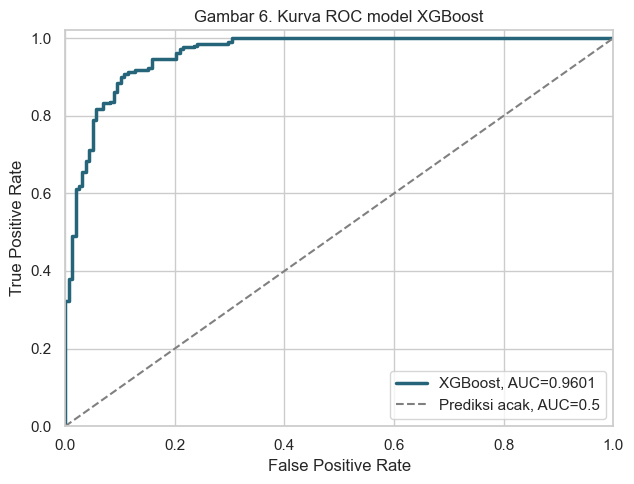

In [14]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(fpr, tpr, lw=2.5, color='#26647a', label=f'XGBoost, AUC={metrics["ROC-AUC"]:.4f}')
ax.plot([0,1], [0,1], '--', color='gray', label='Prediksi acak, AUC=0.5')
ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate',
       title='Gambar 6. Kurva ROC model XGBoost', xlim=(0,1), ylim=(0,1.02))
ax.legend()
plt.tight_layout()
plt.savefig(FIG / '06_roc_curve.png', dpi=160)
plt.show()

**Analisis Gambar 6:** kurva ROC berada jauh di atas garis prediksi acak dengan AUC sekitar **0,9612**. Ini menunjukkan kemampuan pemisahan kelas yang sangat baik di data uji. ROC-AUC mengukur pemisahan kelas pada beragam ambang probabilitas; hasil prediksi final di confusion matrix menggunakan ambang default 0,5.

,feature,importance
3,rain_sum,0.437200
8,weather_code,0.194659
2,precipitation_hours,0.096725
7,temperature_2m_min,0.061426
9,wind_direction_10m_dominant,0.031235
1,month_sin,0.031173
0,month_cos,0.030794
4,sunshine_hours,0.025428
5,temperature_2m_max,0.024233
6,temperature_2m_mean,0.022935


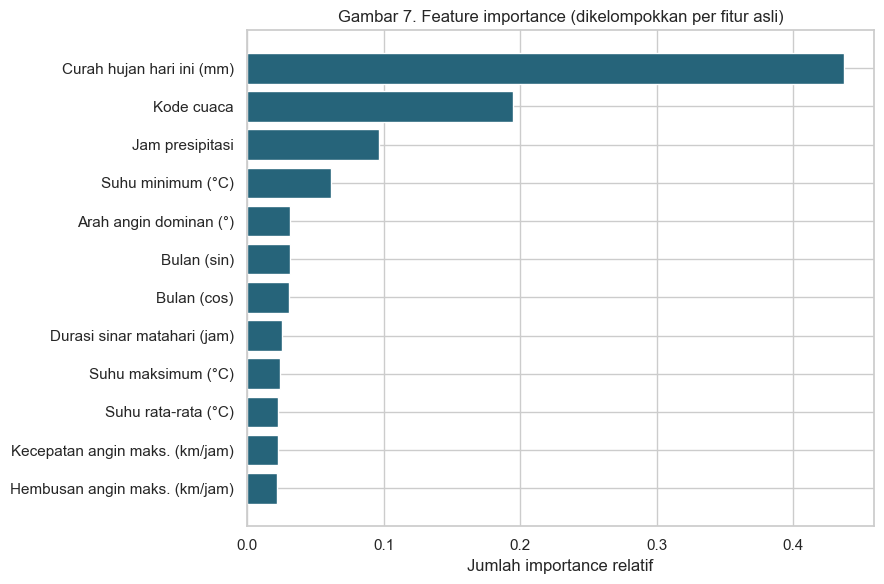

In [15]:
encoded_names = model['preprocessor'].get_feature_names_out()
weights = model['xgboost'].feature_importances_
importance_raw = pd.DataFrame({'encoded_feature': encoded_names, 'importance': weights})
importance_raw['feature'] = importance_raw['encoded_feature'].apply(
    lambda name: 'weather_code' if name.startswith('weather_code_') else name
)
importance = (importance_raw.groupby('feature', as_index=False)['importance']
              .sum().sort_values('importance', ascending=False))
importance['label'] = importance['feature'].map(NAMES)
display(importance[['feature','importance']].head(12))

shown = importance.iloc[:12].iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(shown['label'], shown['importance'], color='#26647a')
ax.set(title='Gambar 7. Feature importance (dikelompokkan per fitur asli)',
       xlabel='Jumlah importance relatif')
plt.tight_layout()
plt.savefig(FIG / '07_feature_importance.png', dpi=160)
plt.show()

**Analisis Gambar 7:** pada model ini `rain_sum` (sekitar **43,37%**), `weather_code` (sekitar **17,73%**), dan `precipitation_hours` (sekitar **9,74%**) menjadi fitur dengan importance tertinggi. Persentase menunjukkan bobot importance relatif menurut model, **bukan** persentase sebab-akibat atau sumbangan langsung terhadap setiap prediksi. One-Hot Encoding kode cuaca digabung kembali agar lebih mudah ditafsirkan.

## Langkah 7 — Mencoba prediksi manual dan menghubungkan dashboard

Untuk simulasi, contoh di bawah memakai nilai cuaca dari baris pertama data test. Anda dapat mengubah angka pada variabel `manual` (jangan menambahkan informasi hari esok). Untuk input dengan form interaktif, jalankan `app.py` menggunakan Streamlit.

In [16]:
manual = X_test.iloc[0].to_dict()
# Contoh mengubah nilai secara manual:
# manual['rain_sum'] = 8.0
# manual['weather_code'] = '61'
manual_df = pd.DataFrame([manual], columns=FEATURES)
manual_pred = int(model.predict(manual_df)[0])
manual_prob = float(model.predict_proba(manual_df)[0,1])
display(manual_df)
print('Hasil:', LABELS[manual_pred])
print(f'Probabilitas hujan besok: {manual_prob:.2%}')

,temperature_2m_mean,temperature_2m_max,temperature_2m_min,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_hours,month_sin,month_cos,weather_code
0,27.6,30.6,25.7,44.8,18.0,8.7,25.2,70,8.173447,1.224647e-16,-1.0,65


Hasil: Hujan
Probabilitas hujan besok: 99.23%


In [17]:
# Simpan model dan prediksi yang bisa digunakan ulang.
joblib.dump(model, OUT / 'model_xgboost_notebook.joblib')
importance.to_csv(OUT / 'feature_importance_notebook.csv', index=False)
predictions = test_df[['time']].copy()
predictions['aktual_hujan_esok'] = y_test.to_numpy()
predictions['prediksi_hujan_esok'] = y_pred
predictions['probabilitas_hujan_esok'] = y_prob
predictions.to_csv(OUT / 'prediksi_data_uji_notebook.csv', index=False)
(OUT / 'metrik_evaluasi_notebook.json').write_text(
    json.dumps({k: float(v) for k,v in metrics.items()}, indent=2), encoding='utf-8'
)
print('File hasil Notebook tersimpan di folder outputs/.')
print('Untuk membuka dashboard Streamlit dari terminal VS Code:')
print('python3 -m streamlit run app.py')

File hasil Notebook tersimpan di folder outputs/.
Untuk membuka dashboard Streamlit dari terminal VS Code:
python3 -m streamlit run app.py


## Langkah 8 — Ringkasan laporan dan kesimpulan

1. **Dataset:** CSV cuaca harian Kolkata; 1.827 baris mentah, 17 kolom; 1.826 observasi valid setelah label hari berikutnya dibentuk.
2. **EDA:** histogram mengungkap variasi kondisi cuaca; heatmap memperlihatkan korelasi antarvariabel; proporsi kelas hujan sekitar 55,9%.
3. **Preprocessing:** drop baris terakhir; turunkan `sunshine_hours`, `month_sin`, `month_cos`; gunakan imputasi dan One-Hot Encoding di dalam Pipeline. Tidak ada standardisasi karena XGBoost berbasis pohon.
4. **Train/test:** split 80:20 berdasarkan waktu, yaitu 1.460 dan 366 sampel; fitting preprocessing hanya dari training.
5. **Hasil model:** accuracy ±89,62%; precision ±88,29%; recall ±94,23%; F1 ±91,16%; ROC-AUC ±0,9612.
6. **Visualisasi:** confusion matrix memperlihatkan 132 TN, 26 FP, 12 FN dan 196 TP. Kurva ROC menunjukkan diskriminasi kelas yang baik. Importance tertinggi ada pada informasi hujan hari ini.
7. **Keterbatasan:** ini model prediksi berbasis agregat harian dari satu lokasi; tidak memprediksi waktu hujan secara jam-jaman atau menjamin akurasi pada lokasi lain.